# MobileNetV2

Basado en los mode

In [21]:
from pathlib import Path

PROJECT_ROOT = Path("plague-identification-model").resolve()

# Configuración de rutas

In [25]:
from pathlib import PurePosixPath

import pandas as pd
import torch
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision.models import MobileNet_V2_Weights

METADATA_PATH = PROJECT_ROOT / "reports" / "split.csv"

# Prefijo original de las rutas del CSV, si vienen de Colab.
OLD_ROOT = PurePosixPath("/content/plague-identification-model")

# OLD_LOCAL_ROOT = None

CLASSES = [
    "mango_gall_midge",
    "tomato_red_mites",
    "tea_green_mirid",
    "tea_helopeltis",
    "tea_red_mites",
    "healthy",
]

CLASS_TO_IDX = {
    label: index
    for index, label in enumerate(CLASSES)
}

# Método para esolver las rutas de las imágenes

In [26]:
def resolve_path(value):
    original = str(value).strip().replace("\\", "/")

    if not original:
        raise ValueError("Se encontró una ruta de imagen vacía.")

    prefixes = [str(OLD_ROOT).rstrip("/")]

    if OLD_LOCAL_ROOT:
        prefixes.append(
            str(OLD_LOCAL_ROOT).replace("\\", "/").rstrip("/")
        )

    for prefix in prefixes:
        if original.startswith(prefix + "/"):
            relative = original[len(prefix) + 1:]
            return PROJECT_ROOT.joinpath(
                *PurePosixPath(relative).parts
            )

    path = Path(original)

    if path.is_absolute():
        return path

    if len(original) >= 2 and original[1] == ":":
        raise ValueError(
            "Se encontró una ruta de Windows. Configura "
            f"OLD_LOCAL_ROOT para resolverla: {original}"
        )

    return PROJECT_ROOT.joinpath(
        *PurePosixPath(original).parts
    )

# Cargar metadata

In [27]:
if not METADATA_PATH.is_file():
    raise FileNotFoundError(
        f"No se encontró el metadata: {METADATA_PATH}"
    )

metadata = pd.read_csv(METADATA_PATH)
metadata = metadata.rename(columns=COLUMN_RENAME)

required = {"path", "final_label", "split"}
missing = required - set(metadata.columns)

if missing:
    raise ValueError(f"Faltan columnas: {sorted(missing)}")

if metadata.empty:
    raise ValueError("El metadata está vacío.")

if metadata[list(required)].isna().any().any():
    raise ValueError(
        "Hay valores vacíos en path, final_label o split."
    )

for column in required:
    metadata[column] = metadata[column].astype(str).str.strip()

# Unificar nombres habituales de partición.
metadata["split"] = (
    metadata["split"]
    .str.lower()
    .replace({
        "val": "validation",
        "valid": "validation",
        "training": "train",
        "testing": "test",
    })
)

unknown_labels = set(metadata["final_label"]) - set(CLASSES)
unknown_splits = set(metadata["split"]) - {
    "train", "validation", "test"
}

if unknown_labels:
    raise ValueError(
        f"Etiquetas desconocidas: {sorted(unknown_labels)}"
    )

if unknown_splits:
    raise ValueError(
        f"Particiones desconocidas: {sorted(unknown_splits)}"
    )

metadata["resolved_path"] = metadata["path"].map(
    lambda value: str(resolve_path(value))
)

missing_files = metadata[
    ~metadata["resolved_path"].map(lambda value: Path(value).is_file())
]

if not missing_files.empty:
    display(
        missing_files[["path", "resolved_path"]].head(10)
    )
    raise FileNotFoundError(
        f"No se encontraron {len(missing_files)} imágenes. "
        "Revisa las rutas y que los archivos estén en el repositorio."
    )

# Detectar la misma ruta asignada a más de una partición.
split_counts = metadata.groupby("resolved_path")["split"].nunique()

if split_counts.gt(1).any():
    raise ValueError(
        "Hay imágenes con la misma ruta en varias particiones."
    )

print("Imágenes del inventario final:", len(metadata))

display(
    pd.crosstab(
        metadata["final_label"],
        metadata["split"]
    ).reindex(index=CLASSES, fill_value=0)
)

Imágenes del inventario final: 6287


split,test,train,validation
final_label,,,
mango_gall_midge,74,347,74
tomato_red_mites,150,700,150
tea_green_mirid,189,883,189
tea_helopeltis,89,418,89
tea_red_mites,76,356,76
healthy,364,1699,364


# MobileNetV2

Sin aumentación

In [28]:
weights = MobileNet_V2_Weights.DEFAULT

train_transform = weights.transforms()
eval_transform = weights.transforms()

print(eval_transform)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


# Datasets y cargadores

In [29]:
class LeafDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        path = Path(row["resolved_path"])

        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image)

            if image.mode != "RGB":
                raise ValueError(
                    f"Imagen no RGB: {path}; modo: {image.mode}"
                )

            tensor = self.transform(image)

        label = CLASS_TO_IDX[row["final_label"]]

        return tensor, label


datasets = {}
loaders = {}

for split in ["train", "validation", "test"]:
    split_df = metadata[metadata["split"] == split].copy()

    if split_df.empty:
        raise ValueError(f"La partición {split} está vacía.")

    transform = (
        train_transform if split == "train"
        else eval_transform
    )

    datasets[split] = LeafDataset(split_df, transform)

    loaders[split] = DataLoader(
        datasets[split],
        batch_size=8,
        shuffle=(split == "train"),
        num_workers=0,
        generator=torch.Generator().manual_seed(42),
    )

    print(f"{split}: {len(datasets[split])} imágenes")

train: 4403 imágenes
validation: 942 imágenes
test: 942 imágenes


# Verificación parcial

In [30]:
for split, loader in loaders.items():
    images, labels = next(iter(loader))

    assert images.ndim == 4
    assert images.shape[1:] == (3, 224, 224)
    assert images.dtype == torch.float32
    assert torch.isfinite(images).all()
    assert labels.min().item() >= 0
    assert labels.max().item() < len(CLASSES)

    print(
        f"{split}: "
        f"imágenes={tuple(images.shape)}, "
        f"tipo={images.dtype}, "
        f"etiquetas={labels.tolist()}"
    )

train: imágenes=(8, 3, 224, 224), tipo=torch.float32, etiquetas=[0, 2, 5, 1, 3, 2, 5, 5]
validation: imágenes=(8, 3, 224, 224), tipo=torch.float32, etiquetas=[5, 5, 5, 5, 5, 5, 5, 5]
test: imágenes=(8, 3, 224, 224), tipo=torch.float32, etiquetas=[5, 5, 5, 5, 5, 5, 5, 5]


# Verificación completa

In [ ]:
for split, loader in loaders.items():
    total_checked = 0

    for images, labels in loader:
        assert images.shape[1:] == (3, 224, 224)
        assert torch.isfinite(images).all()

        total_checked += len(labels)

    print(f"{split}: {total_checked} imágenes procesadas correctamente")

# Visualización final

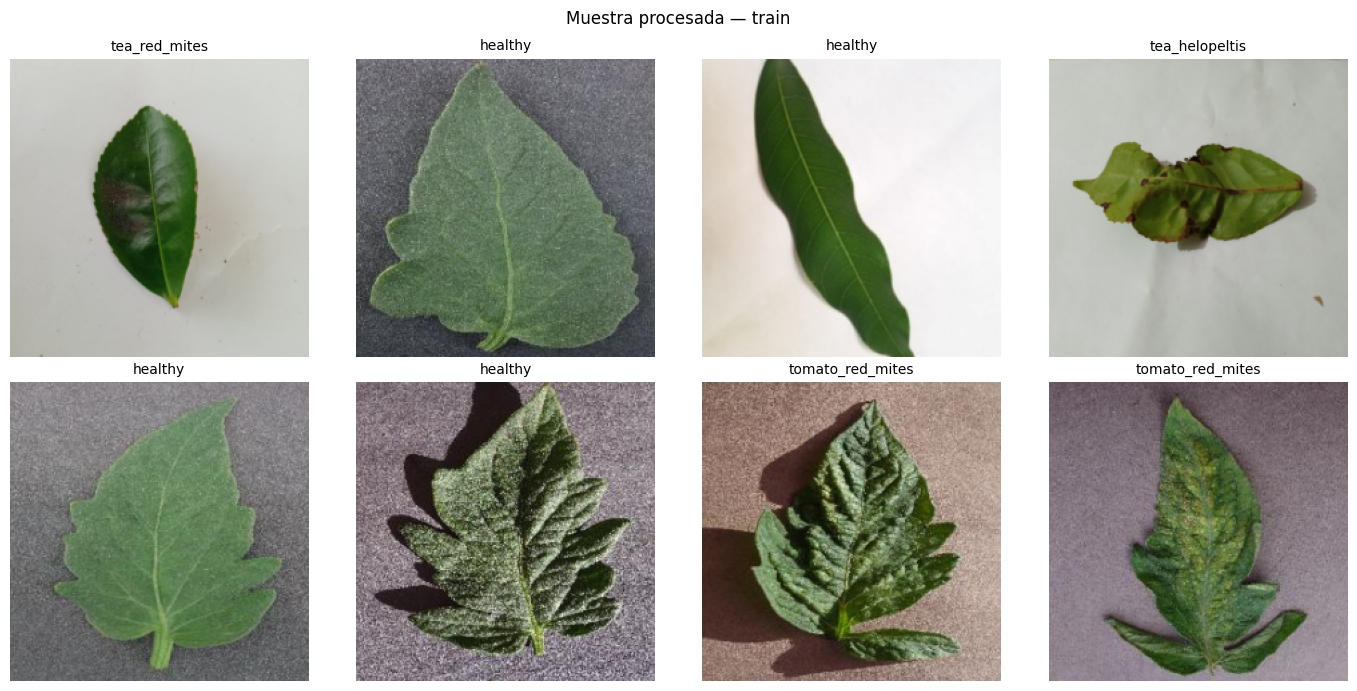

In [32]:
split_to_show = "train"

images, labels = next(iter(loaders[split_to_show]))

mean = torch.tensor(eval_transform.mean).view(3, 1, 1)
std = torch.tensor(eval_transform.std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i in range(min(len(images), len(axes))):
    image = images[i].cpu() * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0)

    axes[i].imshow(image.numpy())
    axes[i].set_title(CLASSES[labels[i].item()], fontsize=10)

fig.suptitle(f"Muestra procesada — {split_to_show}")
plt.tight_layout()

REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

fig.savefig(
    REPORTS / f"processed_batch_{split_to_show}.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()